# EN4554 – Assignment 2: Convolutional Neural Networks

**Name:** Praveen V.V.J.  &nbsp;&nbsp; **Index No:** `220491B`  
**GitHub:** https://github.com/john-praveen/EN4554-Assignment-2

**Contents:** Setup · Task 1 Backpropagation · Task 2 Optimizers · Task 3 Regularization & residual connections · Task 4 Best CNN (optional)

## Setup

This section covers the environment, the fixed seeds, and the CIFAR-10 data pipeline. CIFAR-10 is split 45k train / 5k validation, and each channel is normalised with the **training-split** mean and std. The test set is not touched until Task 4.

In [1]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


In [2]:
from datasets import load_dataset

train_data = load_dataset('uoft-cs/cifar10', split='train')
images = [np.array(img) for img in train_data['img']]
X = torch.tensor(np.stack(images)).permute(0, 3, 1, 2).float() / 255
y = torch.tensor(train_data['label'])

perm = torch.randperm(50000)
X_tr, y_tr = X[perm[:45000]], y[perm[:45000]]
X_va, y_va = X[perm[45000:]], y[perm[45000:]]

mean = X_tr.mean(dim=(0, 2, 3), keepdim=True)
std = X_tr.std(dim=(0, 2, 3), keepdim=True)

X_tr = ((X_tr - mean) / std).to(device)
X_va = ((X_va - mean) / std).to(device)
y_tr = y_tr.to(device)
y_va = y_va.to(device)
print(X_tr.shape, X_va.shape)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


torch.Size([45000, 3, 32, 32]) torch.Size([5000, 3, 32, 32])


In [3]:
def accuracy(model, X, y, bs=1000):
    model.eval()
    correct = 0
    with torch.no_grad():
        for i in range(0, len(X), bs):
            predictions = model(X[i:i + bs]).argmax(1)
            correct += (predictions == y[i:i + bs]).sum().item()
    return correct / len(X)

**Data source.** This is the standard CIFAR-10 training set (50,000 images, 10 classes), loaded with the Hugging Face `datasets` library instead of `torchvision.datasets.CIFAR10`. The download server that `torchvision` uses ran at about 66 kB/s on Colab, an estimated 40 minutes for the 170 MB archive, so I used a faster mirror of the same data.

## Task 1: Backpropagation

### 1(a) Layers with explicit forward and backward

Each layer stores what it needs in `forward` and uses it in `backward`, which receives `dout`, the gradient of the loss with respect to the layer's output, and returns the gradient with respect to its input. The gradients are derived by hand, with no autograd.

| Layer | Forward | Backward |
|---|---|---|
| Linear | `out = x @ W + b` | `dW = xᵀ @ dout`, `db = sum(dout)`, `dx = dout @ Wᵀ` |
| ReLU | `out = max(0, x)` | `dx = dout * (x > 0)` |
| Sigmoid (used in 1d) | `out = 1 / (1 + e^-x)` | `dx = dout * out * (1 - out)` |
| Softmax + cross-entropy | `L = -mean(log softmax(z)[y])` | `dz = (softmax(z) - onehot(y)) / N` |

The softmax and the cross-entropy are combined into one layer because their combined gradient simplifies to `(p - onehot) / N`. Linear weights use He initialisation, `N(0, 2/n_in)`.

In [4]:
class Linear:
    def __init__(self, n_in, n_out):
        self.W = torch.randn(n_in, n_out, device=device) * (2 / n_in) ** 0.5
        self.b = torch.zeros(n_out, device=device)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(0)
        return dout @ self.W.T

class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask

class Sigmoid:
    def forward(self, x):
        self.out = 1 / (1 + torch.exp(-x))
        return self.out

    def backward(self, dout):
        return dout * self.out * (1 - self.out)

class SoftmaxCE:
    def forward(self, logits, y):
        z = logits - logits.max(1, keepdim=True).values
        logp = z - z.logsumexp(1, keepdim=True)
        self.p = logp.exp()
        self.y = y
        rows = torch.arange(len(y), device=y.device)
        return -logp[rows, y].mean()

    def backward(self):
        rows = torch.arange(len(self.y), device=self.y.device)
        d = self.p.clone()
        d[rows, self.y] -= 1
        return d / len(self.y)

class MLP:
    def __init__(self, sizes, act=ReLU):
        self.layers = []
        self.linears = []
        for i in range(len(sizes) - 1):
            linear = Linear(sizes[i], sizes[i + 1])
            self.layers.append(linear)
            self.linears.append(linear)
            if i < len(sizes) - 2:
                self.layers.append(act())
        self.loss_fn = SoftmaxCE()

    def logits(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def forward(self, x, y):
        return self.loss_fn.forward(self.logits(x), y)

    def backward(self):
        d = self.loss_fn.backward()
        for layer in reversed(self.layers):
            d = layer.backward(d)

### 1(b) Gradient check

A small MLP (3072-32-16-10) is checked in float64 on 16 validation images. The manual gradients are compared with:
1. **autograd**, on every entry, using `torch.allclose`;
2. **centred finite differences**, `(L(w+ε) − L(w−ε)) / 2ε` with `ε = 1e-5`, on 50 randomly chosen entries of each parameter tensor. Checking every entry would take too long.

The relative error is `‖a − b‖ / (‖a‖ + ‖b‖)`.

In [5]:
set_seed()
xs = X_va[:16].reshape(16, -1).cpu().double()
ys = y_va[:16].cpu()
net = MLP([3072, 32, 16, 10])
for layer in net.linears:
    layer.W = layer.W.cpu().double()
    layer.b = layer.b.cpu().double()

net.forward(xs, ys)
net.backward()

weights = []
biases = []
for layer in net.linears:
    weights.append(layer.W.clone().requires_grad_())
    biases.append(layer.b.clone().requires_grad_())

h = xs
for k in range(len(weights)):
    h = h @ weights[k] + biases[k]
    if k < len(weights) - 1:
        h = F.relu(h)
F.cross_entropy(h, ys).backward()

def finite_diff(param, indices, eps=1e-5):
    flat = param.view(-1)
    grads = []
    for i in indices:
        old = flat[i].item()
        flat[i] = old + eps
        loss_plus = net.forward(xs, ys).item()
        flat[i] = old - eps
        loss_minus = net.forward(xs, ys).item()
        flat[i] = old
        grads.append((loss_plus - loss_minus) / (2 * eps))
    return torch.tensor(grads, dtype=torch.float64)

def relative_error(a, b):
    return ((a - b).norm() / (a.norm() + b.norm())).item()

checks = []
for k, layer in enumerate(net.linears):
    checks.append((f'W{k + 1}', layer.W, layer.dW, weights[k].grad))
    checks.append((f'b{k + 1}', layer.b, layer.db, biases[k].grad))

for name, param, manual, auto in checks:
    idx = torch.randperm(param.numel())[:50]
    fd = finite_diff(param, idx)
    manual_subset = manual.reshape(-1)[idx]

    err_auto = relative_error(manual, auto)
    ok_auto = torch.allclose(manual, auto, rtol=1e-6, atol=1e-9)
    err_fd = relative_error(manual_subset, fd)
    ok_fd = torch.allclose(manual_subset, fd, rtol=1e-4, atol=1e-7)
    print(f'{name}   vs autograd: {err_auto:.2e}, allclose {ok_auto}   vs finite diff: {err_fd:.2e}, allclose {ok_fd}')

W1   vs autograd: 9.85e-17, allclose True   vs finite diff: 1.64e-10, allclose True
b1   vs autograd: 8.10e-17, allclose True   vs finite diff: 1.92e-10, allclose True
W2   vs autograd: 7.38e-17, allclose True   vs finite diff: 7.50e-11, allclose True
b2   vs autograd: 9.05e-17, allclose True   vs finite diff: 6.07e-11, allclose True
W3   vs autograd: 5.22e-17, allclose True   vs finite diff: 9.42e-11, allclose True
b3   vs autograd: 5.56e-17, allclose True   vs finite diff: 9.16e-11, allclose True


**Interpretation (1b).** The manual gradients match autograd with a relative error of about 1e-16, which is the precision limit of float64, and `torch.allclose` is `True` for all six tensors. They match the centred finite differences to about 1e-10, which is the expected error of the centred difference (ε² = 1e-10 for ε = 1e-5). So the backward passes of `Linear`, `ReLU` and softmax cross-entropy are correct.

### 1(c) Training the MLP with SGD

A 3072-256-128-10 MLP is trained on flattened, normalised images with plain mini-batch SGD (learning rate 0.05, batch size 128, 15 epochs). The update is applied by hand, `W -= lr * dW`.

epoch  1  train loss 1.730  val acc 0.4138
epoch  2  train loss 1.464  val acc 0.4770
epoch  3  train loss 1.351  val acc 0.4848
epoch  4  train loss 1.263  val acc 0.4930
epoch  5  train loss 1.192  val acc 0.5008
epoch  6  train loss 1.130  val acc 0.4864
epoch  7  train loss 1.073  val acc 0.4940
epoch  8  train loss 1.021  val acc 0.5164
epoch  9  train loss 0.968  val acc 0.5064
epoch 10  train loss 0.918  val acc 0.5106
epoch 11  train loss 0.870  val acc 0.4964
epoch 12  train loss 0.827  val acc 0.5164
epoch 13  train loss 0.789  val acc 0.4824
epoch 14  train loss 0.748  val acc 0.4894
epoch 15  train loss 0.712  val acc 0.4908


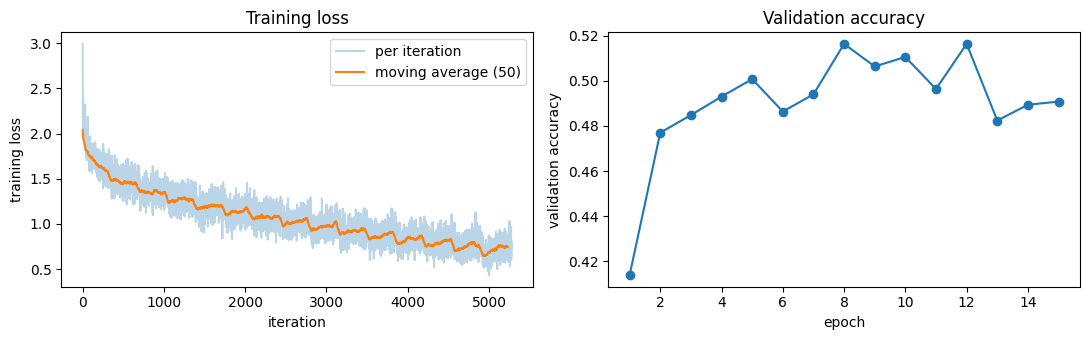

Final validation accuracy: 0.4908


In [6]:
set_seed()
Xf_tr = X_tr.reshape(len(X_tr), -1)
Xf_va = X_va.reshape(len(X_va), -1)
net = MLP([3072, 256, 128, 10])

lr = 0.05
bs = 128
epochs = 15
losses = []
val_accs = []

for ep in range(epochs):
    perm = torch.randperm(len(Xf_tr), device=device)
    epoch_losses = []
    for i in range(0, len(perm), bs):
        idx = perm[i:i + bs]
        loss = net.forward(Xf_tr[idx], y_tr[idx])
        net.backward()
        for layer in net.linears:
            layer.W -= lr * layer.dW
            layer.b -= lr * layer.db
        epoch_losses.append(loss.item())
    losses += epoch_losses

    predictions = net.logits(Xf_va).argmax(1)
    val_accs.append((predictions == y_va).float().mean().item())
    print(f'epoch {ep + 1:2d}  train loss {np.mean(epoch_losses):.3f}  val acc {val_accs[-1]:.4f}')

smooth = np.convolve(losses, np.ones(50) / 50, mode='valid')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(losses, alpha=0.3, label='per iteration')
ax[0].plot(smooth, label='moving average (50)')
ax[0].set_xlabel('iteration')
ax[0].set_ylabel('training loss')
ax[0].set_title('Training loss')
ax[0].legend()
ax[1].plot(range(1, epochs + 1), val_accs, marker='o')
ax[1].set_xlabel('epoch')
ax[1].set_ylabel('validation accuracy')
ax[1].set_title('Validation accuracy')
plt.tight_layout()
plt.show()
print(f'Final validation accuracy: {val_accs[-1]:.4f}')

**Interpretation (1c).**
- The training loss falls steadily from 1.73 to 0.71, so the hand-written backprop and SGD update work.
- Validation accuracy rises to about 48% in two epochs, then stays between 48% and 52% while the training loss keeps falling. The final validation accuracy is **49.1%**. The best epoch was 51.6%, but I report the final epoch so that I do not pick an epoch using the validation set.
- A flat validation curve with a falling training loss means overfitting. An MLP sees the image as 3072 separate numbers and knows nothing about neighbouring pixels, so it memorises the training images instead of learning image features.
- The swings of 2–3% between epochs come from the constant learning rate and the small 5k validation set.
- I chose 15 epochs as a fixed budget. Validation accuracy stopped improving at about epoch 5.

### 1(d) Per-layer gradient norms in a 10-layer MLP at initialisation

A 10-layer MLP (3072 → 256 × 9 → 10, so 10 `Linear` layers) is built with sigmoid and with ReLU. The seed and the He initialisation are the same for both. The only difference is the activation. One backward pass is run on a batch of 256 training images, and the Frobenius norm of `dW` is recorded for each layer.

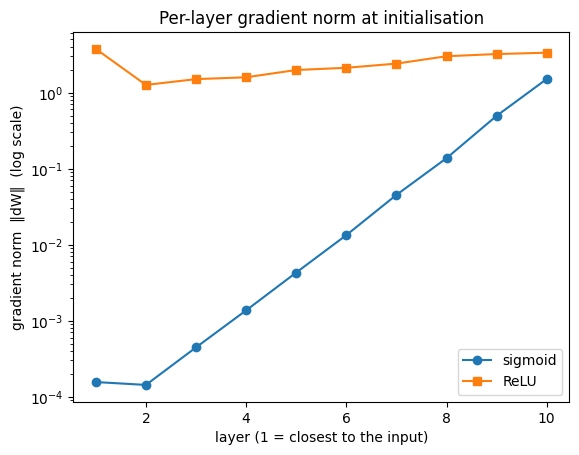

layer  1   sigmoid 1.56e-04   ReLU 3.76e+00
layer  2   sigmoid 1.43e-04   ReLU 1.26e+00
layer  3   sigmoid 4.45e-04   ReLU 1.51e+00
layer  4   sigmoid 1.37e-03   ReLU 1.59e+00
layer  5   sigmoid 4.30e-03   ReLU 1.99e+00
layer  6   sigmoid 1.33e-02   ReLU 2.12e+00
layer  7   sigmoid 4.51e-02   ReLU 2.41e+00
layer  8   sigmoid 1.37e-01   ReLU 3.01e+00
layer  9   sigmoid 4.95e-01   ReLU 3.22e+00
layer 10   sigmoid 1.51e+00   ReLU 3.35e+00


In [7]:
def layer_grad_norms(act):
    set_seed()
    net = MLP([3072] + [256] * 9 + [10], act)
    net.forward(Xf_tr[:256], y_tr[:256])
    net.backward()
    norms = []
    for layer in net.linears:
        norms.append(layer.dW.norm().item())
    return norms

g_sig = layer_grad_norms(Sigmoid)
g_relu = layer_grad_norms(ReLU)

plt.semilogy(range(1, 11), g_sig, marker='o', label='sigmoid')
plt.semilogy(range(1, 11), g_relu, marker='s', label='ReLU')
plt.xlabel('layer (1 = closest to the input)')
plt.ylabel('gradient norm  ‖dW‖  (log scale)')
plt.title('Per-layer gradient norm at initialisation')
plt.legend()
plt.show()

for i in range(10):
    print(f'layer {i + 1:2d}   sigmoid {g_sig[i]:.2e}   ReLU {g_relu[i]:.2e}')

**Interpretation (1d).**
- **Sigmoid:** the gradient norm drops from 1.5 at layer 10 to about 1.5e-4 near the input. That is roughly 3 times smaller per layer and about 10⁴ times over the whole network.
- **ReLU:** the norm stays between 1.3 and 3.8 in every layer.
- **Why:** in the backward pass the gradient is multiplied at each layer by `Wᵀ` and by the derivative of the activation. The sigmoid derivative is at most 0.25 (about 0.2 in practice), and the He-initialised `Wᵀ` scales the gradient by about √2. So each layer multiplies the gradient by about √2 × 0.22 ≈ 0.3, or 1/3, which matches the measured ratio of 3 to 3.6. The ReLU derivative is 1 for active units and 0 for the other half, which cancels the √2 gain, so the gradient size stays about constant.
- This is the **vanishing gradient** problem: the early layers of a deep sigmoid network learn very slowly.
- Layer 1 is larger than layer 2 for both activations because its 3072 × 256 weight matrix has about 12 times more entries.

## Task 2: Optimizers

### 2(a) SGD with momentum and Adam as `torch.optim.Optimizer` subclasses

Update rules, where `g` is the gradient, `lr` the learning rate and `t` the step count:

**SGD with momentum** (the PyTorch convention, with no dampening):
`buf = momentum * buf + g`, then `w = w - lr * buf`. On the first step `buf = g`.

**Adam** with bias correction:
`m = β1 * m + (1 - β1) * g`
`v = β2 * v + (1 - β2) * g²`
`m̂ = m / (1 - β1ᵗ)`, `v̂ = v / (1 - β2ᵗ)`
`w = w - lr * m̂ / (√v̂ + ε)`

Without the bias correction, `m` and `v` start at zero and are biased towards zero in the first steps. Dividing by `(1 - βᵗ)` removes that bias.

To test them, two copies of the same small network start from identical weights and see identical mini-batches. One copy uses my optimizer and the other uses the PyTorch one. After 20 steps the parameters are compared.

In [8]:
class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if group['momentum'] > 0:
                    state = self.state[p]
                    if 'buf' not in state:
                        state['buf'] = g.clone()
                    else:
                        state['buf'].mul_(group['momentum']).add_(g)
                    g = state['buf']
                p.add_(g, alpha=-group['lr'])

class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            b1, b2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue
                state = self.state[p]
                if not state:
                    state['t'] = 0
                    state['m'] = torch.zeros_like(p)
                    state['v'] = torch.zeros_like(p)
                state['t'] += 1
                t = state['t']
                state['m'].mul_(b1).add_(p.grad, alpha=1 - b1)
                state['v'].mul_(b2).addcmul_(p.grad, p.grad, value=1 - b2)
                m_hat = state['m'] / (1 - b1 ** t)
                v_hat = state['v'] / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(group['eps']), value=-group['lr'])

def make_optimizer(name, params, lr):
    if name == 'SGD':
        return MySGD(params, lr=lr)
    if name == 'SGD + momentum':
        return MySGD(params, lr=lr, momentum=0.9)
    return MyAdam(params, lr=lr)

In [9]:
import copy

def run_steps(model, opt, steps=20):
    set_seed()
    for _ in range(steps):
        idx = torch.randint(0, len(X_tr), (128,), device=device)
        loss = F.cross_entropy(model(X_tr[idx]), y_tr[idx])
        opt.zero_grad()
        loss.backward()
        opt.step()

def max_difference(model_a, model_b):
    biggest = 0
    for pa, pb in zip(model_a.parameters(), model_b.parameters()):
        biggest = max(biggest, (pa - pb).abs().max().item())
    return biggest

def compare(label, mine, reference, **kwargs):
    set_seed()
    base = nn.Sequential(nn.Flatten(), nn.Linear(3072, 64), nn.ReLU(), nn.Linear(64, 10)).to(device)
    a = copy.deepcopy(base)
    b = copy.deepcopy(base)
    run_steps(a, mine(a.parameters(), **kwargs))
    run_steps(b, reference(b.parameters(), **kwargs))

    diff = max_difference(a, b)
    moved = max_difference(a, base)
    same = True
    for pa, pb in zip(a.parameters(), b.parameters()):
        if not torch.allclose(pa, pb, rtol=1e-5, atol=1e-6):
            same = False
    print(f'{label:30s} max |difference| = {diff:.2e}   max weight change = {moved:.2e}   allclose: {same}')

compare('SGD (lr=0.01)', MySGD, torch.optim.SGD, lr=0.01)
compare('SGD momentum 0.9 (lr=0.01)', MySGD, torch.optim.SGD, lr=0.01, momentum=0.9)
compare('Adam (lr=1e-3)', MyAdam, torch.optim.Adam, lr=1e-3)
compare('Adam (lr=1e-2)', MyAdam, torch.optim.Adam, lr=1e-2)

SGD (lr=0.01)                  max |difference| = 0.00e+00   max weight change = 9.49e-03   allclose: True
SGD momentum 0.9 (lr=0.01)     max |difference| = 0.00e+00   max weight change = 4.91e-02   allclose: True
Adam (lr=1e-3)                 max |difference| = 2.14e-08   max weight change = 1.71e-02   allclose: True
Adam (lr=1e-2)                 max |difference| = 3.43e-07   max weight change = 1.54e-01   allclose: True


**Interpretation (2a).** `MySGD` matches `torch.optim.SGD` exactly (difference 0), with and without momentum. `MyAdam` matches `torch.optim.Adam` to 2e-8 (lr = 1e-3) and 3e-7 (lr = 1e-2), and `torch.allclose` is `True` in all four cases. The weights did move during the 20 steps, so the match is not trivial. The tiny Adam difference is float32 rounding. PyTorch computes `√v / √(1 − β2ᵗ) + ε` and I compute `√(v / (1 − β2ᵗ)) + ε`, which are equal in exact arithmetic.

### 2(b) Trajectories on an ill-conditioned quadratic

`f(x, y) = ½ (x² + 50 y²)` has gradient `(x, 50y)`. It is 50 times steeper in `y` than in `x`, so the contours are long thin ellipses. All three methods start at `(8, 1)` and take 100 steps. My own optimizer classes from 2(a) are used.

- **SGD**: `lr = 0.03`. Plain gradient descent is stable only for `lr < 2/50 = 0.04`, so this is close to the largest usable value.
- **SGD with momentum**: the same `lr = 0.03`, with `momentum = 0.9`.
- **Adam**: `lr = 0.3`.

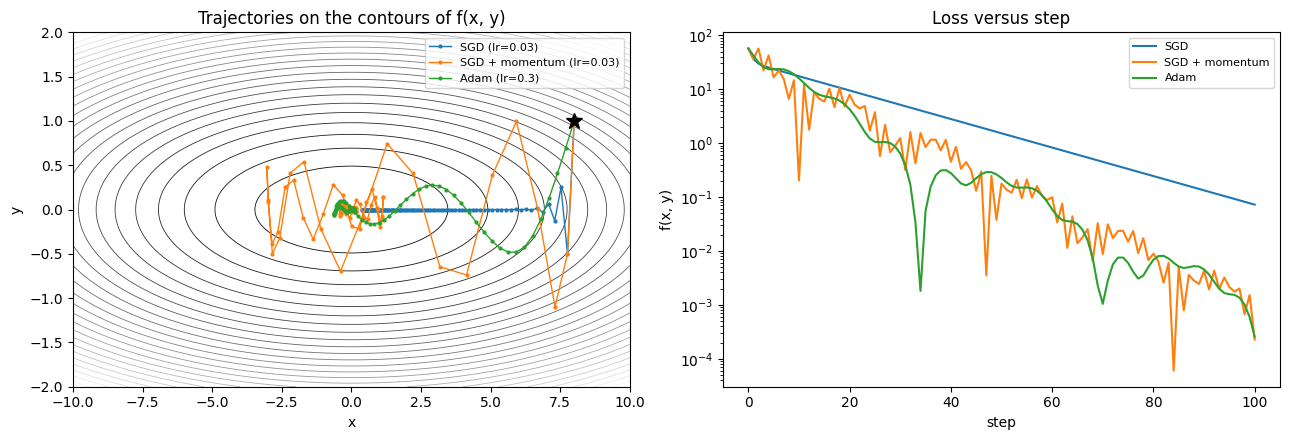

SGD              final point (+0.3804, +0.0000)   final f = 7.236e-02
SGD + momentum   final point (-0.0198, -0.0011)   final f = 2.275e-04
Adam             final point (+0.0194, -0.0016)   final f = 2.562e-04


In [10]:
lr_2b = {'SGD': 0.03, 'SGD + momentum': 0.03, 'Adam': 0.3}

def run_trajectory(name, steps=100, start=(8.0, 1.0)):
    p = torch.tensor(start, requires_grad=True)
    opt = make_optimizer(name, [p], lr_2b[name])
    path = [p.detach().clone().numpy()]
    for _ in range(steps):
        f = 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)
        opt.zero_grad()
        f.backward()
        opt.step()
        path.append(p.detach().clone().numpy())
    return np.array(path)

def f_values(path):
    return 0.5 * (path[:, 0] ** 2 + 50 * path[:, 1] ** 2)

paths = {}
for name in lr_2b:
    paths[name] = run_trajectory(name)

gx, gy = np.meshgrid(np.linspace(-10, 10, 400), np.linspace(-2, 2, 400))
gz = 0.5 * (gx ** 2 + 50 * gy ** 2)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].contour(gx, gy, gz, levels=25, cmap='gray', linewidths=0.6)
for name in paths:
    label = f'{name} (lr={lr_2b[name]})'
    ax[0].plot(paths[name][:, 0], paths[name][:, 1], marker='.', markersize=4, linewidth=1, label=label)
ax[0].plot(8, 1, 'k*', markersize=12)
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('Trajectories on the contours of f(x, y)')
ax[0].legend(fontsize=8)

for name in paths:
    ax[1].semilogy(f_values(paths[name]) + 1e-12, label=name)
ax[1].set_xlabel('step')
ax[1].set_ylabel('f(x, y)')
ax[1].set_title('Loss versus step')
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

for name in paths:
    final = paths[name][-1]
    print(f'{name:16s} final point ({final[0]:+.4f}, {final[1]:+.4f})   final f = {f_values(paths[name])[-1]:.3e}')

**Interpretation (2b).** The function is 50 times steeper in `y` than in `x`, so the contours are long thin ellipses.
- **SGD:** the steep `y` direction forces a small learning rate (it must be below 2/50 = 0.04). With `lr = 0.03`, `y` shrinks fast because it is multiplied by −0.5 each step, but `x` shrinks by only 0.97 per step. After 100 steps `x = 8 × 0.97¹⁰⁰ ≈ 0.38`, so SGD is slow (final f = 7.2e-2). This is the straight line in both plots.
- **SGD with momentum:** it keeps a running velocity, so it moves faster along the flat `x` direction (the effective step is 10 times bigger). It overshoots and zig-zags, so f goes up and down, but it ends at f = 2.3e-4, about 300 times lower than SGD.
- **Adam:** it scales each coordinate's step by the size of that coordinate's recent gradients, so the steep and flat directions get steps of similar size. Its path is a smooth wave that gets smaller, and it ends at f = 2.6e-4.

So momentum and Adam both handle this badly scaled problem better than SGD. I did not tune the learning rates, so this result is only for these settings.

### 2(c) Optimizer sensitivity on a small CNN

A small CNN (three 3×3 conv layers with 32, 64 and 128 channels, each followed by ReLU and 2×2 max-pooling, then one linear layer; about 114k parameters, no batch norm) is trained for 10 epochs with batch size 128 for every optimizer and learning-rate pair. All runs use the same seed, so the initial weights and the batch order are the same and only the optimizer changes. The optimizers are my `MySGD` and `MyAdam` from 2(a).

| Optimizer | Learning rates |
|---|---|
| SGD | 0.001, 0.01, 0.1 |
| SGD + momentum 0.9 | 0.001, 0.01, 0.1 |
| Adam | 0.0001, 0.001, 0.01 |

The rates are a decade apart, so they show how sensitive each optimizer is. A run's score is its validation accuracy after the last epoch, which avoids picking the best epoch on the validation set.

In [11]:
def make_cnn():
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(128 * 4 * 4, 10))

def train_cnn(name, lr, epochs=10, bs=128):
    set_seed()
    model = make_cnn().to(device)
    opt = make_optimizer(name, model.parameters(), lr)
    train_losses = []
    val_accs = []
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(X_tr), device=device)
        total = 0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            loss = F.cross_entropy(model(X_tr[idx]), y_tr[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(idx)
        train_losses.append(total / len(perm))
        val_accs.append(accuracy(model, X_va, y_va))
    return train_losses, val_accs

print('CNN parameters:', sum(p.numel() for p in make_cnn().parameters()))

CNN parameters: 113738


In [12]:
learning_rates = {
    'SGD': [0.001, 0.01, 0.1],
    'SGD + momentum': [0.001, 0.01, 0.1],
    'Adam': [1e-4, 1e-3, 1e-2],
}

results = {}
for name in learning_rates:
    for lr in learning_rates[name]:
        train_losses, val_accs = train_cnn(name, lr)
        results[(name, lr)] = (train_losses, val_accs)
        print(f'{name:15s} lr={lr:<7g} final train loss {train_losses[-1]:.3f}   final val acc {val_accs[-1]:.4f}')

SGD             lr=0.001   final train loss 1.872   final val acc 0.3574
SGD             lr=0.01    final train loss 1.127   final val acc 0.6046
SGD             lr=0.1     final train loss 0.499   final val acc 0.7274
SGD + momentum  lr=0.001   final train loss 1.103   final val acc 0.6018
SGD + momentum  lr=0.01    final train loss 0.445   final val acc 0.7502
SGD + momentum  lr=0.1     final train loss 1.191   final val acc 0.5686
Adam            lr=0.0001  final train loss 1.047   final val acc 0.6186
Adam            lr=0.001   final train loss 0.352   final val acc 0.7530
Adam            lr=0.01    final train loss 1.272   final val acc 0.5368


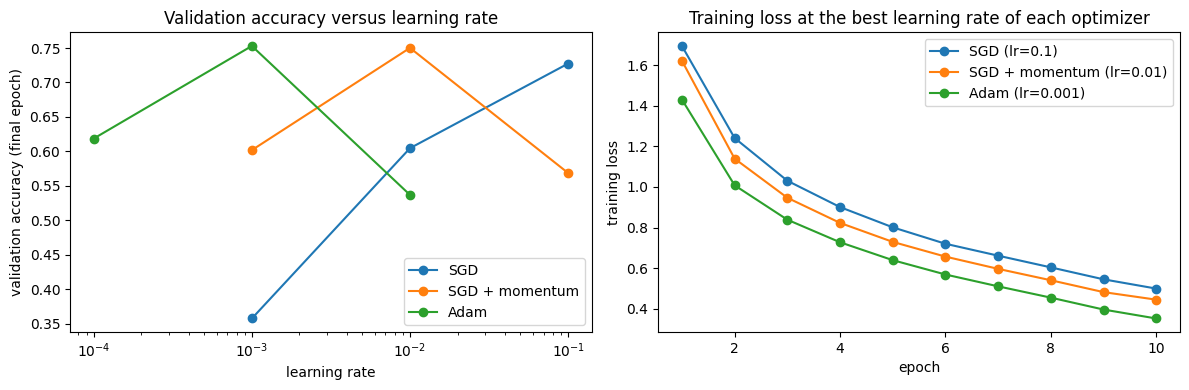

In [13]:
best_lr = {}

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name in learning_rates:
    lrs = learning_rates[name]
    accs = []
    for lr in lrs:
        accs.append(results[(name, lr)][1][-1])
    ax[0].plot(lrs, accs, marker='o', label=name)
    best_lr[name] = lrs[accs.index(max(accs))]
ax[0].set_xscale('log')
ax[0].set_xlabel('learning rate')
ax[0].set_ylabel('validation accuracy (final epoch)')
ax[0].set_title('Validation accuracy versus learning rate')
ax[0].legend()

for name in best_lr:
    train_losses = results[(name, best_lr[name])][0]
    ax[1].plot(range(1, len(train_losses) + 1), train_losses, marker='o', label=f'{name} (lr={best_lr[name]:g})')
ax[1].set_xlabel('epoch')
ax[1].set_ylabel('training loss')
ax[1].set_title('Training loss at the best learning rate of each optimizer')
ax[1].legend()
plt.tight_layout()
plt.show()

**Interpretation (2c).**

| Optimizer | lr | Final train loss | Final val acc |
|---|---|---|---|
| SGD | 0.001 | 1.872 | 0.357 |
| SGD | 0.01 | 1.127 | 0.605 |
| SGD | **0.1** | 0.499 | **0.727** |
| SGD + momentum | 0.001 | 1.103 | 0.602 |
| SGD + momentum | **0.01** | 0.445 | **0.750** |
| SGD + momentum | 0.1 | 1.191 | 0.569 |
| Adam | 0.0001 | 1.047 | 0.619 |
| Adam | **0.001** | 0.352 | **0.753** |
| Adam | 0.01 | 1.272 | 0.537 |

**Sensitivity.** All three optimizers are sensitive: a 10 times change in learning rate costs 12 to 25 accuracy points.
- **SGD** improves with every step up in learning rate. Its best rate (0.1) is at the edge of my grid, so the true best rate may be higher.
- **Momentum** (best 0.01) and **Adam** (best 0.001) peak in the middle. A rate that is too small trains slowly, and one that is too large is unstable (final train loss 1.19 for momentum at 0.1 and 1.27 for Adam at 0.01).
- The best rates differ by about 10 times because momentum 0.9 makes the effective step `1 / (1 − 0.9) = 10` times larger. Momentum at 0.001 (60.2%) behaves like SGD at 0.01 (60.5%). So the learning rate must be tuned again whenever the optimizer changes.

**Training loss at the best rate.** Adam is lowest (0.352), then momentum (0.445), then SGD (0.499), so Adam trains fastest. Validation accuracy is 75.3% for Adam, 75.0% for momentum and 72.7% for SGD. The 0.3-point gap between Adam and momentum is not meaningful. With the same seed, GPU non-determinism alone moved momentum's best result from 76.2% to 75.0% between two runs. So Adam and momentum are about equal, and both are about 2–3 points better than SGD. I tried only three rates per optimizer, so the true best rates may lie between them.

## Task 3: Regularization and residual connections

### 3(a) Regularization on a small CNN with 5k training images

With only 5,000 training images, a CNN overfits quickly, which makes the effect of each regularizer easy to see. The network has three conv blocks (conv, batch norm, ReLU, 2×2 max-pool) with 32, 64 and 128 channels, then a linear layer. It is trained on the first 5,000 images of the training split and evaluated on the full 5k validation split.

Seven runs are compared. They all use the same seed, so the initial weights and the batch order are the same.

| Run | What it does |
|---|---|
| baseline | no regularization |
| weight decay | L2 penalty, `weight_decay = 5e-4` |
| dropout | `Dropout(0.5)` before the final linear layer |
| flip + crop | random horizontal flip, then a random 32×32 crop of the image padded by 4 pixels |
| cutout | one random 16×16 square of every image is set to 0 (the mean colour after normalisation) |
| mixup | each batch is mixed with a shuffled copy of itself, `x = λ·x₁ + (1−λ)·x₂`, with `λ ~ Beta(1, 1)`. The loss is `λ·CE(y₁) + (1−λ)·CE(y₂)` |
| all combined | all five of the above together |

Cutout and mixup are implemented by hand below. Every run uses SGD (momentum 0.9, lr 0.05), cosine learning-rate decay and 100 epochs. Train accuracy is measured on the clean 5k training images in eval mode, so it is comparable between runs.

In [23]:
class SmallCNN(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.features = nn.Sequential(
            self.conv_block(3, 32),
            self.conv_block(32, 64),
            self.conv_block(64, 128),
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(128 * 4 * 4, 10)

    def conv_block(self, c_in, c_out):
        return nn.Sequential(
            nn.Conv2d(c_in, c_out, 3, padding=1),
            nn.BatchNorm2d(c_out),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

    def forward(self, x):
        x = self.features(x).flatten(1)
        return self.fc(self.dropout(x))

In [24]:
def flip_and_crop(x, pad=4):
    n = len(x)
    flip = torch.rand(n, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    padded = F.pad(x, (pad, pad, pad, pad))
    shifts = torch.randint(0, 2 * pad + 1, (n, 2)).tolist()
    out = torch.empty_like(x)
    for i, (dy, dx) in enumerate(shifts):
        out[i] = padded[i, :, dy:dy + 32, dx:dx + 32]
    return out

def cutout(x, size=16):
    n, c, h, w = x.shape
    cy = torch.randint(0, h, (n, 1, 1), device=x.device)
    cx = torch.randint(0, w, (n, 1, 1), device=x.device)
    rows = torch.arange(h, device=x.device).view(1, h, 1)
    cols = torch.arange(w, device=x.device).view(1, 1, w)
    in_rows = (rows >= cy - size // 2) & (rows < cy + size // 2)
    in_cols = (cols >= cx - size // 2) & (cols < cx + size // 2)
    hole = in_rows & in_cols
    return x * (~hole).unsqueeze(1)

def mixup(x, y, alpha=1.0):
    lam = np.random.beta(alpha, alpha)
    order = torch.randperm(len(x), device=x.device)
    mixed = lam * x + (1 - lam) * x[order]
    return mixed, y, y[order], lam

In [25]:
X_small = X_tr[:5000]
y_small = y_tr[:5000]

def train_small(use_wd=False, dropout=0.0, use_flipcrop=False, use_cutout=False, use_mixup=False, epochs=100, bs=128):
    set_seed()
    model = SmallCNN(dropout).to(device)
    weight_decay = 5e-4 if use_wd else 0.0
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    history = {'train_acc': [], 'val_acc': []}

    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(X_small), device=device)
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            xb, yb = X_small[idx], y_small[idx]
            if use_flipcrop:
                xb = flip_and_crop(xb)
            if use_cutout:
                xb = cutout(xb)
            if use_mixup:
                xb, y_a, y_b, lam = mixup(xb, yb)
                out = model(xb)
                loss = lam * F.cross_entropy(out, y_a) + (1 - lam) * F.cross_entropy(out, y_b)
            else:
                loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
        scheduler.step()
        history['train_acc'].append(accuracy(model, X_small, y_small))
        history['val_acc'].append(accuracy(model, X_va, y_va))
    return history

In [26]:
runs_3a = {
    'baseline': {},
    'weight decay': {'use_wd': True},
    'dropout': {'dropout': 0.5},
    'flip + crop': {'use_flipcrop': True},
    'cutout': {'use_cutout': True},
    'mixup': {'use_mixup': True},
    'all combined': {'use_wd': True, 'dropout': 0.5, 'use_flipcrop': True, 'use_cutout': True, 'use_mixup': True},
}

histories = {}
for name in runs_3a:
    histories[name] = train_small(**runs_3a[name])
    print(f'{name:14s} done   train acc {histories[name]["train_acc"][-1]:.4f}   val acc {histories[name]["val_acc"][-1]:.4f}')

print()
print(f"{'method':14s} {'train acc':>10s} {'val acc':>9s} {'gap':>8s}")
for name in histories:
    train_acc = histories[name]['train_acc'][-1]
    val_acc = histories[name]['val_acc'][-1]
    print(f'{name:14s} {train_acc:10.4f} {val_acc:9.4f} {train_acc - val_acc:8.4f}')

baseline       done   train acc 0.9998   val acc 0.5236
weight decay   done   train acc 1.0000   val acc 0.5430
dropout        done   train acc 0.9858   val acc 0.6436
flip + crop    done   train acc 0.7508   val acc 0.6658
cutout         done   train acc 0.9714   val acc 0.6044
mixup          done   train acc 0.6632   val acc 0.5192
all combined   done   train acc 0.3982   val acc 0.3818

method          train acc   val acc      gap
baseline           0.9998    0.5236   0.4762
weight decay       1.0000    0.5430   0.4570
dropout            0.9858    0.6436   0.3422
flip + crop        0.7508    0.6658   0.0850
cutout             0.9714    0.6044   0.3670
mixup              0.6632    0.5192   0.1440
all combined       0.3982    0.3818   0.0164


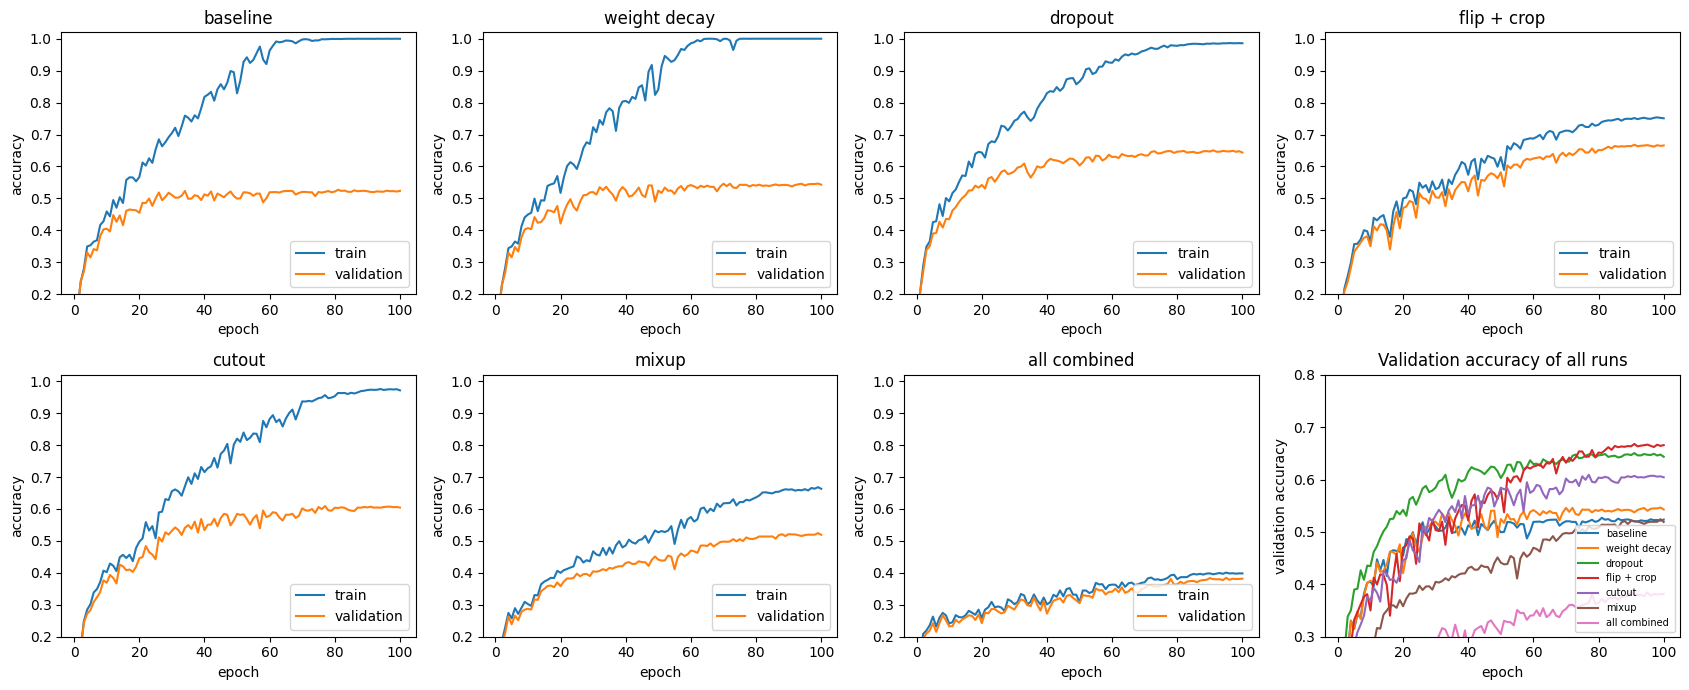

In [28]:
epoch_axis = range(1, len(histories['baseline']['train_acc']) + 1)
fig, axes = plt.subplots(2, 4, figsize=(17, 7))

for ax, name in zip(axes.flat, histories):
    ax.plot(epoch_axis, histories[name]['train_acc'], label='train')
    ax.plot(epoch_axis, histories[name]['val_acc'], label='validation')
    ax.set_title(name)
    ax.set_xlabel('epoch')
    ax.set_ylabel('accuracy')
    ax.set_ylim(0.2, 1.02)
    ax.legend(loc='lower right')

ax = axes.flat[7]
for name in histories:
    ax.plot(epoch_axis, histories[name]['val_acc'], label=name)
ax.set_title('Validation accuracy of all runs')
ax.set_xlabel('epoch')
ax.set_ylabel('validation accuracy')
ax.set_ylim(0.3, 0.8)
ax.legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.show()

**Interpretation (3a).**

| Method | Train acc | Val acc | Gap |
|---|---|---|---|
| baseline | 0.9998 | 0.5236 | 0.4762 |
| weight decay | 1.0000 | 0.5430 | 0.4570 |
| dropout | 0.9858 | 0.6436 | 0.3422 |
| flip + crop | 0.7508 | **0.6658** | 0.0850 |
| cutout | 0.9714 | 0.6044 | 0.3670 |
| mixup | 0.6632 | 0.5192 | 0.1440 |
| all combined | 0.3982 | 0.3818 | 0.0164 |

- **Baseline:** it reaches 100% train accuracy but only 52.4% on validation, a gap of 47.6 points. With 5k images the network memorises the training set. Validation stops improving after about 25 epochs.
- **Weight decay:** almost no effect (54.3%, only 1.9 points better). A likely reason is that with batch norm the output does not change when the conv weights are scaled, so the L2 penalty mostly changes the effective learning rate and does not limit how well the network can fit.
- **Dropout:** a clear gain (64.4%, +12 points) even though it is used only before the last layer. Random zeroing of features stops the last layer from relying on a few features.
- **Flip + crop:** the best method (66.6%, +14 points) with a small gap of 8.5 points. Train accuracy is lower (75%) because the images change every epoch, so they cannot be memorised. These transformations also teach the network that a shifted or flipped image has the same label, which is like having more data.
- **Cutout:** a moderate gain (60.4%, +8 points), but the gap is still large (36.7 points).
- **Mixup:** no gain (51.9%, about the same as the baseline). Train accuracy is only 66% and still rising at epoch 100, so the network is **underfitting**. Mixup makes the task harder and probably needs longer training.
- **All combined:** the worst validation accuracy (38.2%). The gap is the smallest (1.6 points), but only because the network cannot even fit the training data (train accuracy 39.8%). Five strong regularizers together are too much for this small network and 100 epochs.

A small gap alone does not mean a good model. The best result needs both a small gap and a high validation accuracy, and flip + crop gives that. This is one seed and the validation set has 5k images (standard error about 0.7%), so differences of 1 to 2 points, such as weight decay against baseline, are not reliable.

### 3(b) Plain versus residual networks of depth 8, 20 and 56

CIFAR-style networks of depth `6n + 2` with `n = 1, 3, 9` (depths 8, 20 and 56). Each network has a 3×3 conv layer with 16 channels, then three stages of `n` blocks with 16, 32 and 64 channels, global average pooling and a linear layer. Every conv layer is followed by batch norm, and all conv and linear weights use Kaiming initialisation.

Each block is `conv → BN → ReLU → conv → BN`. **The only difference between the two families is the shortcut.** In the residual family the block input is added to the block output before the final ReLU, and the plain family has no shortcut. When a stage halves the image size and doubles the channels, the shortcut subsamples the input by 2 and pads the extra channels with zeros, so the shortcut has no parameters and both families have exactly the same number of parameters.

Both families are trained on all 45k training images with no data augmentation, so that the training loss shows how well each network can be optimised. SGD (lr 0.05, momentum 0.9, weight decay 5e-4), batch size 128, 15 epochs.

In [19]:
class Block(nn.Module):
    def __init__(self, c_in, c_out, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.stride = stride
        self.extra_channels = c_out - c_in
        self.residual = residual

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            shortcut = x
            if self.stride == 2:
                shortcut = x[:, :, ::2, ::2]
                half = self.extra_channels // 2
                shortcut = F.pad(shortcut, (0, 0, 0, 0, half, half))
            out = out + shortcut
        return F.relu(out)

class CifarNet(nn.Module):
    def __init__(self, n, residual):
        super().__init__()
        self.conv = nn.Conv2d(3, 16, 3, padding=1, bias=False)
        self.bn = nn.BatchNorm2d(16)
        blocks = []
        c_in = 16
        for c_out, stride in [(16, 1), (32, 2), (64, 2)]:
            for k in range(n):
                block_stride = stride if k == 0 else 1
                blocks.append(Block(c_in, c_out, block_stride, residual))
                c_in = c_out
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(64, 10)
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')

    def forward(self, x):
        x = F.relu(self.bn(self.conv(x)))
        x = self.blocks(x)
        x = x.mean(dim=(2, 3))
        return self.fc(x)

for n in [1, 3, 9]:
    plain = sum(p.numel() for p in CifarNet(n, False).parameters())
    resnet = sum(p.numel() for p in CifarNet(n, True).parameters())
    print(f'depth {6 * n + 2:2d}: plain {plain:,} parameters, residual {resnet:,} parameters')

depth  8: plain 75,290 parameters, residual 75,290 parameters
depth 20: plain 269,722 parameters, residual 269,722 parameters
depth 56: plain 853,018 parameters, residual 853,018 parameters


In [20]:
import time

def train_cifarnet(n, residual, epochs=15, bs=128, lr=0.05):
    set_seed()
    model = CifarNet(n, residual).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)
    train_losses = []
    val_accs = []
    start = time.time()

    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(X_tr), device=device)
        total = 0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            loss = F.cross_entropy(model(X_tr[idx]), y_tr[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(idx)
        train_losses.append(total / len(perm))
        val_accs.append(accuracy(model, X_va, y_va))
        if (ep + 1) % 5 == 0:
            print(f'   epoch {ep + 1:2d}   train loss {train_losses[-1]:.3f}   val acc {val_accs[-1]:.4f}   ({time.time() - start:.0f}s)')
    return train_losses, val_accs

In [21]:
results_3b = {}
for n in [1, 3, 9]:
    for residual in [False, True]:
        family = 'residual' if residual else 'plain'
        print(f'depth {6 * n + 2}, {family}')
        results_3b[(n, residual)] = train_cifarnet(n, residual)

depth 8, plain
   epoch  5   train loss 0.767   val acc 0.6350   (27s)
   epoch 10   train loss 0.583   val acc 0.6962   (54s)
   epoch 15   train loss 0.502   val acc 0.7044   (81s)
depth 8, residual
   epoch  5   train loss 0.807   val acc 0.6708   (28s)
   epoch 10   train loss 0.608   val acc 0.6350   (57s)
   epoch 15   train loss 0.529   val acc 0.7146   (85s)
depth 20, plain
   epoch  5   train loss 0.686   val acc 0.7082   (82s)
   epoch 10   train loss 0.496   val acc 0.6372   (165s)
   epoch 15   train loss 0.422   val acc 0.7258   (247s)
depth 20, residual
   epoch  5   train loss 0.595   val acc 0.7472   (85s)
   epoch 10   train loss 0.402   val acc 0.7586   (170s)
   epoch 15   train loss 0.309   val acc 0.7762   (255s)
depth 56, plain
   epoch  5   train loss 1.730   val acc 0.3468   (248s)
   epoch 10   train loss 1.370   val acc 0.4714   (497s)
   epoch 15   train loss 1.055   val acc 0.4764   (745s)
depth 56, residual
   epoch  5   train loss 0.634   val acc 0.7492   

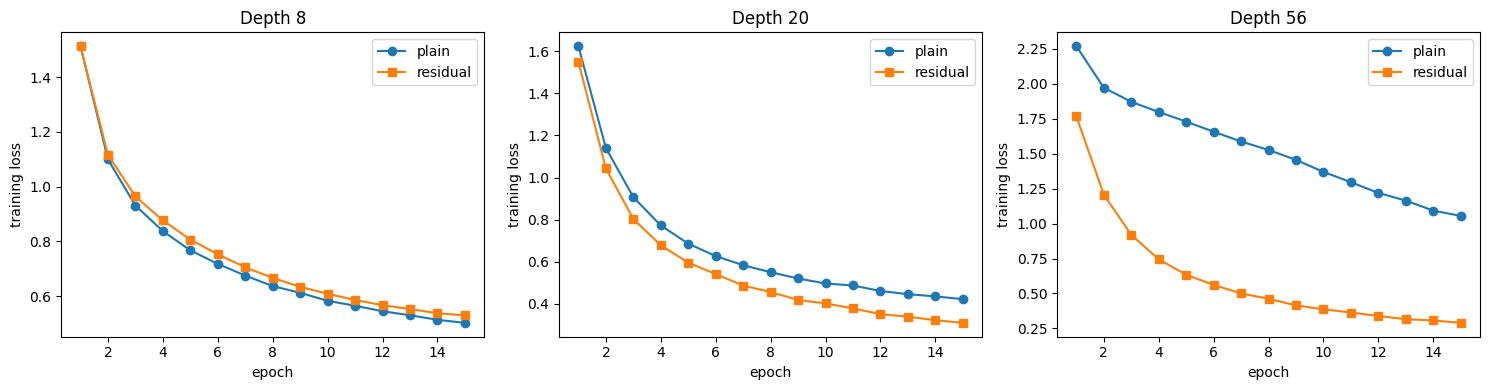

depth    family  final train loss  final val acc
    8     plain             0.502         0.7044
    8  residual             0.529         0.7146
   20     plain             0.422         0.7258
   20  residual             0.309         0.7762
   56     plain             1.055         0.4764
   56  residual             0.290         0.7574


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, n in zip(axes, [1, 3, 9]):
    plain_losses = results_3b[(n, False)][0]
    resnet_losses = results_3b[(n, True)][0]
    ax.plot(range(1, len(plain_losses) + 1), plain_losses, marker='o', label='plain')
    ax.plot(range(1, len(resnet_losses) + 1), resnet_losses, marker='s', label='residual')
    ax.set_title(f'Depth {6 * n + 2}')
    ax.set_xlabel('epoch')
    ax.set_ylabel('training loss')
    ax.legend()
plt.tight_layout()
plt.show()

print(f"{'depth':>5s} {'family':>9s} {'final train loss':>17s} {'final val acc':>14s}")
for n in [1, 3, 9]:
    for residual in [False, True]:
        losses, accs = results_3b[(n, residual)]
        family = 'residual' if residual else 'plain'
        print(f'{6 * n + 2:5d} {family:>9s} {losses[-1]:17.3f} {accs[-1]:14.4f}')

**Interpretation (3b).**

| Depth | Family | Final train loss | Final val acc |
|---|---|---|---|
| 8 | plain | 0.502 | 0.704 |
| 8 | residual | 0.529 | 0.715 |
| 20 | plain | 0.422 | 0.726 |
| 20 | residual | **0.309** | **0.776** |
| 56 | plain | 1.055 | 0.476 |
| 56 | residual | **0.290** | **0.757** |

- **Depth 8:** the two curves almost overlap (0.502 and 0.529). At this depth the shortcut makes no real difference.
- **Depth 20:** the residual network has a lower training loss from epoch 2 on (0.309 against 0.422).
- **Depth 56:** the gap is very large. The plain network starts at a loss of 2.27, which is close to random guessing (ln 10 = 2.30), and it is still at 1.06 after 15 epochs. The residual network reaches 0.290.

**Degradation problem.** The plain 56-layer network has 853k parameters, but its training loss is higher than that of the plain 8-layer network with 75k parameters (1.055 against 0.502). A bigger network should fit the training set at least as well, so this is not overfitting. It is an optimisation problem. The residual networks do not show it: their loss keeps going down as depth grows (0.529, 0.309, 0.290).

**Why.** A residual block computes `x + F(x)`. The identity term lets the gradient reach the early layers directly, and the block can learn `F(x) ≈ 0` to simply pass its input on, so extra blocks do not have to hurt. A plain network must learn this through many stacked layers, and its gradient is a product of many layer terms. Batch norm and Kaiming initialisation keep it trainable, but at 56 layers that is not enough.

**Limits.** This is one seed, with a constant learning rate and only 15 epochs. The plain 56-layer loss was still falling, so a longer run would help it. Validation accuracy jumps between epochs (plain-20: 63.7% at epoch 10, 72.6% at epoch 15), so small validation differences at depths 8 and 20 are noise. Training loss is the cleaner measure here.

## Task 4: The best CNN under 500k parameters and 20 epochs

### Design

The model is a small ResNet for CIFAR-10, built from the `Block` class of Task 3(b). Each choice below comes from an earlier result in this notebook.

| Choice | Value | Reason |
|---|---|---|
| Architecture | residual network, 3 stages of 3 blocks (depth 20), widths 20 / 40 / 80 | Task 3(b): shortcuts make the network easier to train. The widths use most of the 500k budget. |
| Augmentation | random flip and random crop | Task 3(a): the best regularizer on its own. |
| Weight decay | 5e-4 | A standard value for ResNets. |
| Optimizer | SGD, momentum 0.9, Nesterov | Task 2(c): SGD with momentum was as good as Adam. |
| Learning-rate schedule | one-cycle (warm up, then decay to almost 0), batch size 128 | With only 20 epochs, a rate that decays to almost zero usually gives a better final accuracy than a constant rate. |
| Epochs | 20 | The limit. |


- All tuning uses the 45k / 5k train / validation split. The test set is not touched until the last cell.
- **Tuning:** I try three peak learning rates and keep the one with the best final validation accuracy.
- **Ablation:** starting from the tuned model, I change one design choice at a time (remove the shortcut, remove augmentation, remove weight decay, use Adam instead of SGD). Everything else stays the same, and every run uses the same seed.
- **Test:** the final model is evaluated on the test set once.

In [29]:
class BestNet(nn.Module):
    def __init__(self, n=3, widths=(20, 40, 80), residual=True):
        super().__init__()
        self.conv = nn.Conv2d(3, widths[0], 3, padding=1, bias=False)
        self.bn = nn.BatchNorm2d(widths[0])
        blocks = []
        c_in = widths[0]
        for stage, c_out in enumerate(widths):
            for k in range(n):
                stride = 2 if (stage > 0 and k == 0) else 1
                blocks.append(Block(c_in, c_out, stride, residual))
                c_in = c_out
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(widths[-1], 10)
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')

    def forward(self, x):
        x = F.relu(self.bn(self.conv(x)))
        x = self.blocks(x)
        x = x.mean(dim=(2, 3))
        return self.fc(x)

n_params = sum(p.numel() for p in BestNet().parameters())
print(f'BestNet parameters: {n_params:,}')
assert n_params <= 500_000

BestNet parameters: 420,670


In [30]:
def train_best(residual=True, augment=True, weight_decay=5e-4, optimizer='sgd', max_lr=0.1, epochs=20, bs=128):
    set_seed()
    model = BestNet(residual=residual).to(device)
    if optimizer == 'sgd':
        opt = torch.optim.SGD(model.parameters(), lr=max_lr, momentum=0.9, nesterov=True, weight_decay=weight_decay)
    else:
        opt = torch.optim.Adam(model.parameters(), lr=max_lr, weight_decay=weight_decay)
    steps_per_epoch = (len(X_tr) + bs - 1) // bs
    scheduler = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=max_lr, epochs=epochs, steps_per_epoch=steps_per_epoch)
    history = {'train_loss': [], 'val_acc': []}
    start = time.time()

    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(X_tr), device=device)
        total = 0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            xb, yb = X_tr[idx], y_tr[idx]
            if augment:
                xb = flip_and_crop(xb)
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            scheduler.step()
            total += loss.item() * len(idx)
        history['train_loss'].append(total / len(perm))
        history['val_acc'].append(accuracy(model, X_va, y_va))
        if (ep + 1) % 5 == 0:
            print(f'   epoch {ep + 1:2d}   train loss {history["train_loss"][-1]:.3f}   val acc {history["val_acc"][-1]:.4f}   ({time.time() - start:.0f}s)')
    return model, history

### Step 1: tune the peak learning rate

Three peak learning rates are tried with the full design (residual network, augmentation, weight decay, SGD). The best one, judged by the validation accuracy after the last epoch, is used for everything that follows.

In [31]:
tuning_lrs = [0.05, 0.1, 0.2]
tuning_models = {}
tuning_histories = {}

for lr in tuning_lrs:
    print(f'peak lr = {lr}')
    tuning_models[lr], tuning_histories[lr] = train_best(max_lr=lr)

best_lr = None
best_acc = 0
for lr in tuning_lrs:
    acc = tuning_histories[lr]['val_acc'][-1]
    print(f'peak lr {lr:<5}  final train loss {tuning_histories[lr]["train_loss"][-1]:.3f}   final val acc {acc:.4f}')
    if acc > best_acc:
        best_acc = acc
        best_lr = lr
print(f'Best peak learning rate: {best_lr}  (val acc {best_acc:.4f})')

peak lr = 0.05
   epoch  5   train loss 0.801   val acc 0.6902   (119s)
   epoch 10   train loss 0.508   val acc 0.7900   (236s)
   epoch 15   train loss 0.370   val acc 0.8538   (354s)
   epoch 20   train loss 0.213   val acc 0.8988   (472s)
peak lr = 0.1
   epoch  5   train loss 0.720   val acc 0.7194   (117s)
   epoch 10   train loss 0.499   val acc 0.7664   (235s)
   epoch 15   train loss 0.376   val acc 0.8516   (353s)
   epoch 20   train loss 0.188   val acc 0.9052   (470s)
peak lr = 0.2
   epoch  5   train loss 0.709   val acc 0.6794   (117s)
   epoch 10   train loss 0.547   val acc 0.6944   (235s)
   epoch 15   train loss 0.426   val acc 0.8494   (353s)
   epoch 20   train loss 0.189   val acc 0.9078   (471s)
peak lr 0.05   final train loss 0.213   final val acc 0.8988
peak lr 0.1    final train loss 0.188   final val acc 0.9052
peak lr 0.2    final train loss 0.189   final val acc 0.9078
Best peak learning rate: 0.2  (val acc 0.9078)


### Step 2: ablation

Starting from the tuned model (the "full model"), one design choice is changed at a time.

| Run | Change from the full model |
|---|---|
| no shortcut | the same network without the shortcut connections (plain network) |
| no augmentation | no flip and no crop |
| no weight decay | `weight_decay = 0` |
| Adam instead of SGD | `Adam` with peak learning rate 0.003 and the same weight decay |

The Adam learning rate was not tuned, so that row is a quick check and not a fully fair comparison.

In [32]:
ablations = {
    'no shortcut': {'residual': False},
    'no augmentation': {'augment': False},
    'no weight decay': {'weight_decay': 0.0},
    'Adam instead of SGD': {'optimizer': 'adam', 'max_lr': 0.003},
}

ablation_histories = {'full model': tuning_histories[best_lr]}
for name in ablations:
    print(name)
    settings = {'max_lr': best_lr}
    settings.update(ablations[name])
    model, ablation_histories[name] = train_best(**settings)
    del model

full_acc = ablation_histories['full model']['val_acc'][-1]
print()
print(f"{'run':22s} {'train loss':>11s} {'val acc':>9s} {'change':>9s}")
for name in ablation_histories:
    train_loss = ablation_histories[name]['train_loss'][-1]
    val_acc = ablation_histories[name]['val_acc'][-1]
    print(f'{name:22s} {train_loss:11.3f} {val_acc:9.4f} {val_acc - full_acc:+9.4f}')

no shortcut
   epoch  5   train loss 0.820   val acc 0.6220   (114s)
   epoch 10   train loss 0.661   val acc 0.7202   (228s)
   epoch 15   train loss 0.531   val acc 0.7956   (341s)
   epoch 20   train loss 0.271   val acc 0.8884   (454s)
no augmentation
   epoch  5   train loss 0.601   val acc 0.5838   (115s)
   epoch 10   train loss 0.433   val acc 0.7236   (231s)
   epoch 15   train loss 0.265   val acc 0.7748   (347s)
   epoch 20   train loss 0.010   val acc 0.8818   (462s)
no weight decay
   epoch  5   train loss 0.654   val acc 0.7320   (118s)
   epoch 10   train loss 0.415   val acc 0.8086   (236s)
   epoch 15   train loss 0.285   val acc 0.8774   (355s)
   epoch 20   train loss 0.169   val acc 0.9030   (473s)
Adam instead of SGD
   epoch  5   train loss 0.839   val acc 0.6604   (119s)
   epoch 10   train loss 0.565   val acc 0.7682   (238s)
   epoch 15   train loss 0.381   val acc 0.8566   (356s)
   epoch 20   train loss 0.210   val acc 0.8998   (474s)

run                    

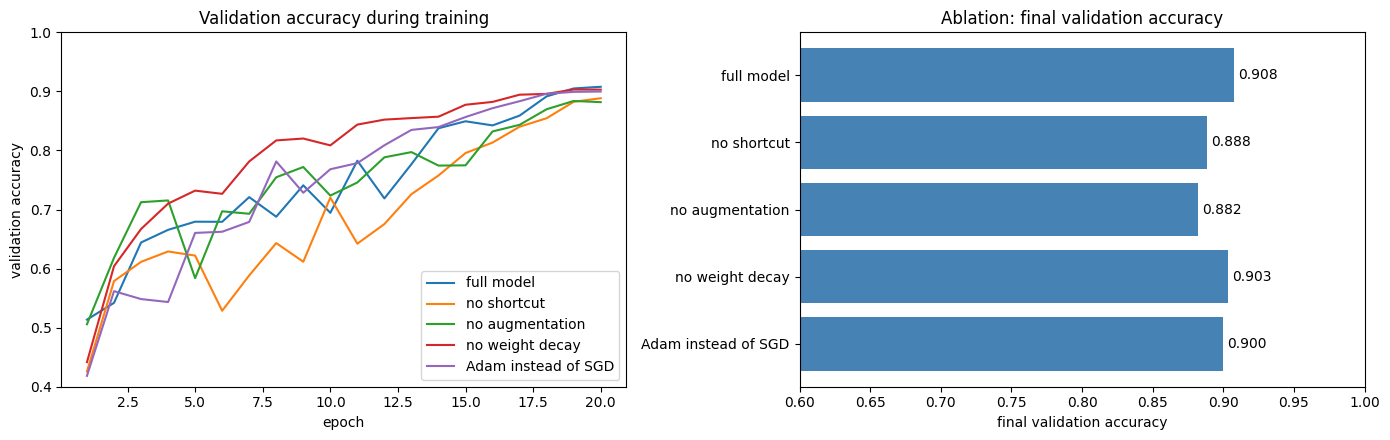

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name in ablation_histories:
    accs = ablation_histories[name]['val_acc']
    ax[0].plot(range(1, len(accs) + 1), accs, label=name)
ax[0].set_xlabel('epoch')
ax[0].set_ylabel('validation accuracy')
ax[0].set_title('Validation accuracy during training')
ax[0].set_ylim(0.4, 1.0)
ax[0].legend(loc='lower right')

names = list(ablation_histories)
finals = []
for name in names:
    finals.append(ablation_histories[name]['val_acc'][-1])
ax[1].barh(names, finals, color='steelblue')
ax[1].set_xlim(0.6, 1.0)
ax[1].set_xlabel('final validation accuracy')
ax[1].set_title('Ablation: final validation accuracy')
ax[1].invert_yaxis()
for i, value in enumerate(finals):
    ax[1].text(value + 0.003, i, f'{value:.3f}', va='center')
plt.tight_layout()
plt.show()

### Step 3: final test accuracy

The test set is loaded here for the first time, normalised with the training mean and std, and the final model is evaluated once. The final model is the full model trained with the best peak learning rate, and it was chosen using the validation split only. 

In [34]:
final_model = tuning_models[best_lr]

test_data = load_dataset('uoft-cs/cifar10', split='test')
test_images = [np.array(img) for img in test_data['img']]
X_te = torch.tensor(np.stack(test_images)).permute(0, 3, 1, 2).float() / 255
X_te = ((X_te - mean) / std).to(device)
y_te = torch.tensor(test_data['label']).to(device)

test_acc = accuracy(final_model, X_te, y_te)
n_params = sum(p.numel() for p in final_model.parameters())
print(f'Final model: {n_params:,} parameters, 20 epochs')
print(f'Validation accuracy: {ablation_histories["full model"]["val_acc"][-1]:.4f}')
print(f'Test accuracy:       {test_acc:.4f}')

Final model: 420,670 parameters, 20 epochs
Validation accuracy: 0.9078
Test accuracy:       0.9050


**Interpretation (Task 4).**

Tuning of the peak learning rate (full model, SGD):

| Peak lr | Final train loss | Final val acc |
|---|---|---|
| 0.05 | 0.213 | 0.8988 |
| 0.1 | 0.188 | 0.9052 |
| **0.2** | 0.189 | **0.9078** |

Ablation (one change from the full model):

| Run | Final train loss | Final val acc | Change |
|---|---|---|---|
| full model | 0.189 | 0.9078 | 0 |
| no shortcut | 0.271 | 0.8884 | −1.9 points |
| no augmentation | 0.010 | 0.8818 | −2.6 points |
| no weight decay | 0.169 | 0.9030 | −0.5 points |
| Adam instead of SGD | 0.210 | 0.8998 | −0.8 points |

- **Learning rate:** all three rates give between 89.9% and 90.8%, so the model is not very sensitive to it. The best rate (0.2) is at the edge of my grid, and its 0.3-point lead over 0.1 is within noise.
- **Augmentation** matters most (−2.6 points). Without it the training loss falls to 0.010, so the network memorises the training set and generalises worse.
- **Shortcut** is the second most important (−1.9 points). The plain network has a higher training loss (0.271 against 0.189), which agrees with Task 3(b): it is harder to optimise. At depth 20 the effect is smaller than at depth 56.
- **Weight decay** (−0.5) and **Adam** (−0.8) change the result only a little, which is within noise, so I cannot say that either one helps. The Adam row also changes the learning rate (0.003, not tuned), so it is only a rough check.
- **Noise:** this is one seed and a 5k validation set, and earlier runs with the same seed differed by about 1 point. Only the augmentation and shortcut effects are clearly larger than that.
- **Learning curves:** validation accuracy is noisy in the middle of training and climbs quickly in the last epochs, when the one-cycle schedule brings the learning rate close to zero. This is what lets a short 20-epoch run reach about 90%.

**Final result:** the full model (420,670 parameters, 20 epochs) has a **test accuracy of 90.50%**, evaluated once. Its validation accuracy was 90.78%, only 0.3 points higher, so choosing between three learning rates on the validation set did not give an over-optimistic estimate.